In [ ]:
import tensorflow as tf

                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
(50000, 2)
Vocabulary size: 56262
Training shape: (40000, 100)
Testing shape: (10000, 100)


D:\DL\dl_env\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8478 - loss: 0.3500 - val_accuracy: 0.8675 - val_loss: 0.3136
Epoch 2/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8666 - loss: 0.3176 - val_accuracy: 0.8643 - val_loss: 0.3210
Epoch 3/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8688 - loss: 0.3099 - val_accuracy: 0.8710 - val_loss: 0.3104
Epoch 4/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8706 - loss: 0.3061 - val_accuracy: 0.8715 - val_loss: 0.3099
Epoch 5/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8745 - loss: 0.3011 - val_accuracy: 0.8740 - val_loss: 0.3038
Epoch 6/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8756 - loss: 0.2966 - val_accuracy: 0.8740 - val_loss: 0.3056
Epoch 7/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8785 - loss: 0.2930 - val_accuracy: 0.8730 - val_loss: 0.3059
Epoch 8/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8796 - loss: 0.2887 - 

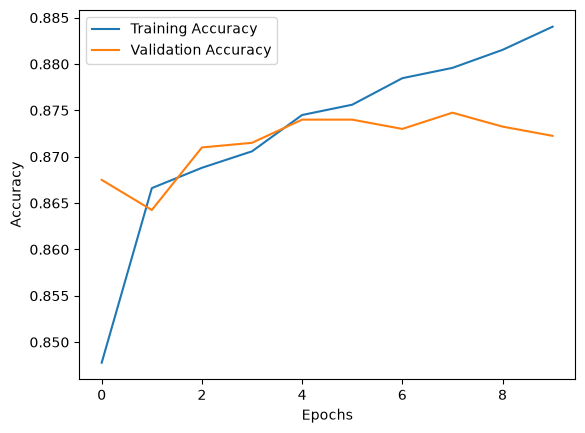

In [6]:

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.preprocessing import LabelEncoder

from gensim.models import Word2Vec
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# 1. Load dataset
data = pd.read_csv(r"D:\DL\LP IV Updated Datasets\CBOW\IMDB Dataset.csv")
data = data.dropna()

print(data.head())
print(data.shape)

# 2. Separate reviews and labels
x = data['review'].str.lower()
y = LabelEncoder().fit_transform(data['sentiment'])

# 3. Split dataset
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

# 4. Preprocessing
stop_words = set(ENGLISH_STOP_WORDS)

def preprocess(text):
    words = re.findall(r'\b[a-z]+\b', text)
    return [word for word in words if word not in stop_words]

sentences = [preprocess(text) for text in x_train]
test_sentences = [preprocess(text) for text in x_test]

# 5. Train CBOW Word2Vec
word2vec = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    sg=0,
    epochs=10
)

print("Vocabulary size:", len(word2vec.wv))

# 6. Convert documents into embeddings
def get_embedding(words):
    vectors = [word2vec.wv[word] for word in words
               if word in word2vec.wv]

    if len(vectors) == 0:
        return np.zeros(100)

    return np.mean(vectors, axis=0)

x_train_emb = np.array([get_embedding(words) for words in sentences])
x_test_emb = np.array([get_embedding(words) for words in test_sentences])

print("Training shape:", x_train_emb.shape)
print("Testing shape:", x_test_emb.shape)

# 7. Build Feed Forward Neural Network
model = Sequential([
    Dense(64, activation='relu', input_shape=(100,)),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

# 8. Compile model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 9. Train model
history = model.fit(
    x_train_emb,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

# 10. Evaluate on test data
loss, accuracy = model.evaluate(x_test_emb, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# 11. Plot accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()
